In [1]:
pip install firebase-admin pandas matplotlib

This code initializes Firebase services within a Python notebook by
setting up a secure connection to a Firestore database using the Firebase
Admin SDK. It begins by importing the firebase_admin module, which is
necessary to access Firebase services through Python. From this module,
it specifically imports:


• Credentials, which are used to authenticate access


• Firestore, which allows interaction with Firebase's NoSQL database

In [11]:
import firebase_admin
from firebase_admin import credentials, firestore

# Check if the Firebase app is already initialized to prevent ValueError on re-runs
if not firebase_admin._apps:
    # loads a service account key stored in a JSON file
    cred = credentials.Certificate('/content/firebase.json')
    # activates the Firebase Admin SDK using the loaded credentials
    firebase_admin.initialize_app(cred)

# creates a client instance specifically for your 'firebasedb' Cloud Firestore database
db = firestore.client(database_id='firebasedb')

In [12]:
def log_event(event_type, user_id, details):
    doc_ref = db.collection('agent_logs').document()
    doc_ref.set({
        'eventType': event_type,
        'userId': user_id,
        'details': details,
        'timestamp': firestore.SERVER_TIMESTAMP
    })
log_event('approve', 'user_123', {'action': 'Book room for 2 at $100/night'})

In [14]:
import pandas as pd

def get_all_logs():
    # Retrieve all documents from the 'agent_logs' collection
    logs_ref = db.collection('agent_logs')
    docs = logs_ref.stream()

    # Store the retrieved data into a list of dictionaries
    logs_list = []
    for doc in docs:
        log_data = doc.to_dict()
        log_data['document_id'] = doc.id
        logs_list.append(log_data)

    # Create a DataFrame for nice visualization
    if logs_list:
        df = pd.DataFrame(logs_list)
        # Ensure timestamp is readable
        if 'timestamp' in df.columns:
            df['timestamp'] = pd.to_datetime(df['timestamp'])
        return df
    else:
        print("No logs found in the collection.")
        return None

# Fetch and display the logs
logs_df = get_all_logs()
if logs_df is not None:
    display(logs_df)

,userId,details,timestamp,eventType,document_id
0,user_123,{'action': 'Book room for 2 at $100/night'},2026-10-10 15:38:02.643000+00:00,approve,0wt0ogky4Xl0tQrkR9k4


In [16]:
def fetch_events():
    docs = db.collection('agent_logs').order_by('timestamp',
direction=firestore.Query.DESCENDING).stream()
    events = []
    for doc in docs:
        data = doc.to_dict()
        data['timestamp'] = data['timestamp'].strftime('%Y-%m-%d %H:%M:%S') if data['timestamp'] else None
        events.append(data)
    return events
events_data = fetch_events()

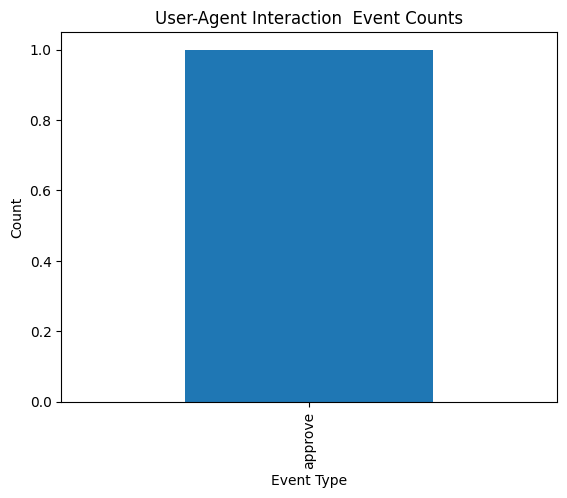

In [18]:
# PLot visualizations
import pandas as pd
import matplotlib.pyplot as plt
df = pd.DataFrame(events_data)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['eventType'].value_counts().plot(kind='bar', title='User-Agent Interaction  Event Counts')
plt.xlabel('Event Type')
plt.ylabel('Count')
plt.show()

In [19]:
from IPython.display import display
display(df[['eventType', 'userId', 'timestamp', 'details']])

,eventType,userId,timestamp,details
0,approve,user_123,2026-10-10 15:38:02,{'action': 'Book room for 2 at $100/night'}
